# 0 · What can Riemannian distance fields do?

This tutorial is about one idea: **describe what makes a motion expensive with a Riemannian
metric $G$, compute the distance field of that metric, and read off optimal motions from its
gradient.**  The recipe is always the same:

1. **a space** with coordinates $q$ — positions of a mobile robot or of an end-effector, joint
   angles of an arm, the state of a cart-pole, ...;
2. **a metric** $G(q)$ — a positive-definite matrix at every point saying how costly it is to
   move in each direction (inertia, energy, distance to obstacles, stability, ...);
3. **a distance field** $U$ — solution of the Riemannian eikonal equation
   $\|\nabla U\|_{G^{-1}}=1$, computed on a grid or learned by a neural network (NES);
4. **geodesics and policies** — the flow $-G^{-1}\nabla U$ points along the shortest motion
   from anywhere, so following it gives optimal paths and reactive feedback controllers.

Changing the task means changing the metric; the machinery does not change.  This notebook
shows the results first — each example is a few lines using models trained in the later
notebooks, which explain how everything works.  All examples are 2-D so that they can be
plotted, but nothing in the method is specific to 2-D or to joint space: the paper uses the
same network for a 7-joint arm.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, nes, obstacles as obs, control as ct, plotting as P
from geodf.robots import PlanarArm, CartPole

pi = np.pi
arm = PlanarArm()
box = [-pi, -pi], [pi, pi]


def load(model, path):
    model.load_state_dict(torch.load(path)["state"])
    return model.eval()


def geodesics(model, G, goal, starts, **kw):
    goal = torch.as_tensor(goal, dtype=torch.float32)
    src = goal.expand(len(starts), -1) if goal.ndim == 1 else goal
    return nes.backtrack(model, src, torch.as_tensor(np.asarray(starts), dtype=torch.float32), G, **kw)


def field_on_grid(model, goal, bounds, n=120, w=None):
    gx = np.linspace(*bounds[0], n); gy = np.linspace(*bounds[1], n)
    X, Y = np.meshgrid(gx, gy, indexing="ij")
    Q = torch.as_tensor(np.stack([X.ravel(), Y.ravel()], -1), dtype=torch.float32)
    S = torch.as_tensor(goal, dtype=torch.float32).expand_as(Q)
    U = (model(S, Q) if w is None else model(S, Q, w)).detach().numpy().reshape(n, n)
    return X, Y, U

## 1. Navigating around obstacles in the plane (task space)

A point robot moves in the plane.  The metric makes motion close to an obstacle expensive —
above all motion *towards* it, while motion around it stays comparatively cheap.  One distance field to the goal (red star) gives the
path from every start — and they keep a safe distance.  *(Notebook 6.)*

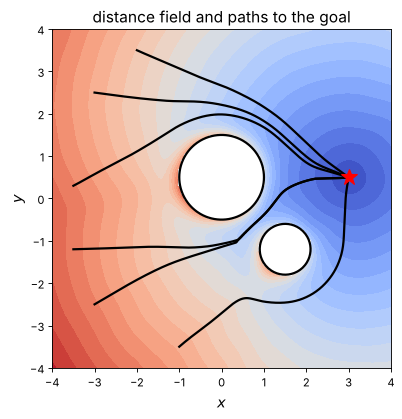

In [2]:
sdf = obs.disc_sdf([[0.0, 0.5], [1.5, -1.2]], [1.0, 0.6])
G_plane = obs.speed_scaled(metrics.obstacle_metric(sdf, alpha=5.0, tau=0.5, phi_min=0.1), sdf)
m_plane = load(nes.NES([-4, -4], [4, 4]), "checkpoints/nes_plane_riem.pt")
goal = np.array([3.0, 0.5])
starts = np.array([(-3.5, 0.3), (-3.0, 2.5), (-3.0, -2.5), (-1.0, -3.5), (-3.5, -1.2), (-2.0, 3.5)])
X, Y, U = field_on_grid(m_plane, goal, ((-4, 4), (-4, 4)))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.contourf(X, Y, np.where(sdf(torch.as_tensor(np.stack([X, Y], -1))).numpy() < 0, np.nan, U), 25, cmap="coolwarm")
ax.contour(X, Y, sdf(torch.as_tensor(np.stack([X, Y], -1))).numpy(), [0], colors="k", linewidths=2)
for p in geodesics(m_plane, G_plane, goal, starts, step=0.01, tol=0.03):
    ax.plot(*p.T, "k-", lw=2)
ax.plot(*goal, "r*", ms=15)
P.setup_ax(ax, bounds=((-4, 4), (-4, 4)), labels=("$x$", "$y$"), title="distance field and paths to the goal")
plt.show()

## 2. Moving a robot arm with less effort (joint space)

For a 2-link arm, the configuration space is the square of joint angles $(q_1,q_2)$.  With the
inertia matrix $M$ as metric, the length of a motion is $\int\sqrt{2T}\,dt$ ($T$ = kinetic
energy): it measures how much the arm's masses have to be moved.  The geodesic
keeps the elbow folded (a light, compact arm) while it swings the shoulder; the straight
joint-space line costs about 25 % more.  *(Notebooks 1-3.)*

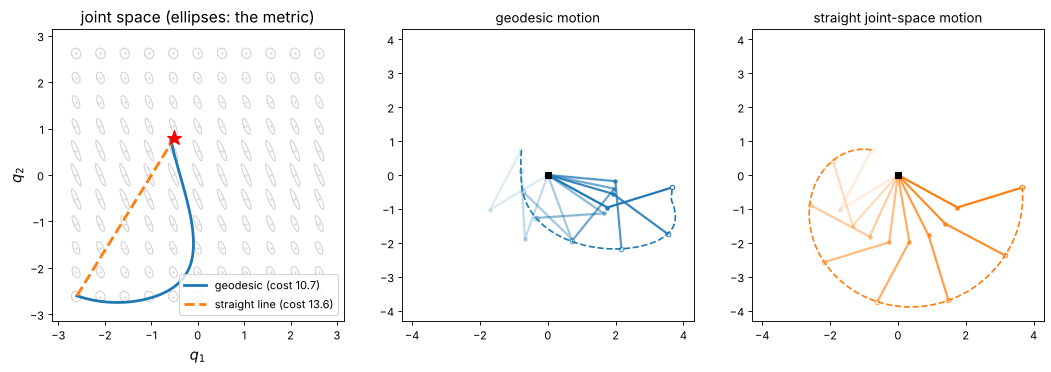

In [3]:
G_ke = metrics.kinetic_energy(arm)
m_ke = load(nes.NES(*box), "checkpoints/nes_ke.pt")
q_goal, q_start = np.array([-0.5, 0.8]), np.array([-2.6, -2.6])
geo = geodesics(m_ke, G_ke, q_goal, [q_start], step=0.01, tol=0.03)[0]
line = np.linspace(q_start, q_goal, len(geo))
L = lambda p: metrics.metric_length(G_ke, torch.as_tensor(p)).item()

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
P.metric_ellipses(axs[0], G_ke, density=11, color="lightgray")
axs[0].plot(*geo.T, "tab:blue", lw=2.5, label=f"geodesic (cost {L(geo):.1f})")
axs[0].plot(*line.T, "tab:orange", lw=2.5, ls="--", label=f"straight line (cost {L(line):.1f})")
axs[0].plot(*q_goal, "r*", ms=14); axs[0].legend(loc="lower right")
P.setup_ax(axs[0], title="joint space (ellipses: the metric)")
P.arm_motion(axs[1], arm, geo, "tab:blue"); axs[1].set_title("geodesic motion")
P.arm_motion(axs[2], arm, line, "tab:orange"); axs[2].set_title("straight joint-space motion")
plt.show()

## 3. Reaching a point in the workspace without inverse kinematics

The goal can be given in a *different* space than the one we move in.  Here the target is an
end-effector position; the network measures the distance from any joint configuration to the
whole set of configurations that reach it.  Following the flow picks, for each start, the
reachable configuration that is cheapest to get to — no IK solver involved.  *(Notebook 4.)*

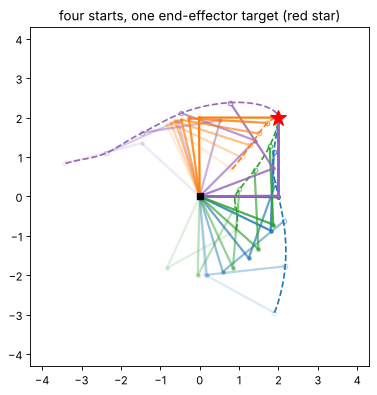

In [4]:
reach = arm.l1 + arm.l2
m_task = load(nes.TaskNES(arm.fk, [-reach, -reach], [reach, reach], *box), "checkpoints/cnes_task_ke.pt")
xs = torch.tensor([2.0, 2.0])
starts = np.array([[-1.5, 1.0], [-2.0, 2.5], [2.4, 1.0], [2.0, -2.6]])
paths = nes.backtrack(m_task, xs.expand(4, 2), torch.as_tensor(starts, dtype=torch.float32), G_ke, step=0.01,
                      tol=0.02, goal_fn=lambda q: torch.linalg.norm(arm.fk(q) - xs, dim=-1))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, c in zip(paths, ["tab:blue", "tab:green", "tab:purple", "tab:orange"]):
    P.arm_motion(ax, arm, p, c, n=6)
ax.plot(*xs, "r*", ms=15)
ax.set_title("four starts, one end-effector target (red star)")
plt.show()

## 4. Straight end-effector paths

Measuring a joint motion by how far the end-effector moves (the metric $J^\top J$) turns
geodesics into motions whose end-effector travels in straight lines.  *(Notebook 6.)*

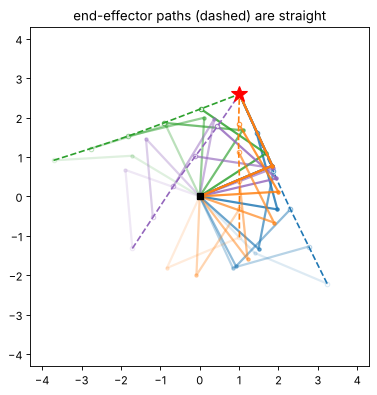

In [5]:
G_pb = metrics.pullback(arm, reg=0.01)
m_pb = load(nes.NES(*box, metric=G_pb), "checkpoints/nes_pullback.pt")
q_goal = np.array([0.4, 1.6])
starts = np.array([[-0.8, 0.4], [2.6, 0.6], [2.8, 2.0], [-2.0, 2.4]])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, c in zip(geodesics(m_pb, G_pb, q_goal, starts, step=0.005, tol=0.03), ["tab:blue", "tab:green", "tab:purple", "tab:orange"]):
    P.arm_motion(ax, arm, p, c, n=6)
ax.plot(*arm.fk(torch.as_tensor(q_goal[None]))[0].numpy(), "r*", ms=15)
ax.set_title("end-effector paths (dashed) are straight")
plt.show()

## 5. Stable motions for a cart-pole (a state space mixing position and angle)

The space can mix very different coordinates: here the cart position $x$ and the pole angle
$\theta$.  A metric that grows with the potential energy of the pole makes geodesics keep the
pole low while the cart travels far, and lift it only at the goal (upright pole at $x=9$).
*(Notebook 6.)*

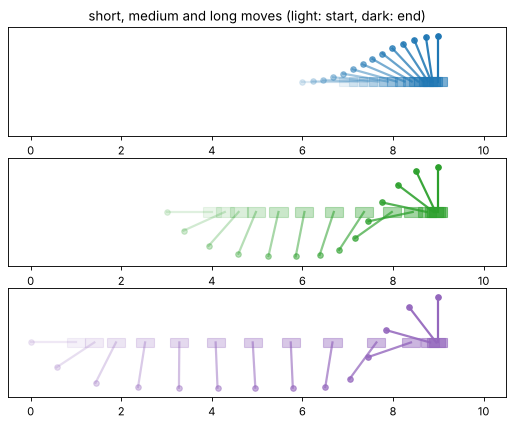

In [6]:
cp = CartPole()
G_cp = metrics.stability_aware(cp, eps=2.0)
m_cp = load(nes.NES([0.0, -pi], [10.0, pi]), "checkpoints/nes_cartpole.pt")
paths = geodesics(m_cp, G_cp, np.array([9.0, 0.0]), np.array([[7.0, -pi / 2], [4.0, -pi / 2], [1.0, -pi / 2]]),
                  step=0.01, tol=0.03)
fig, axs = plt.subplots(3, 1, figsize=(13, 6))
for ax, p, c in zip(axs, paths, ["tab:blue", "tab:green", "tab:purple"]):
    for j, i in enumerate(np.linspace(0, len(p) - 1, 14).astype(int)):
        P.draw_cartpole(ax, p[i, 0], p[i, 1], color=c, alpha=0.15 + 0.85 * j / 13)
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.set_yticks([])
axs[0].set_title("short, medium and long moves (light: start, dark: end)")
plt.show()

## 6. One network for a whole family of metrics

When the metric depends on a parameter, the parameter can be an input of the network.  Here the
metric is the Jacobi metric of the arm under gravity, whose geodesics are the arm's free,
energy-conserving motions at total energy $H$.  One network gives the geodesics for every $H$.
*(Notebook 4.)*

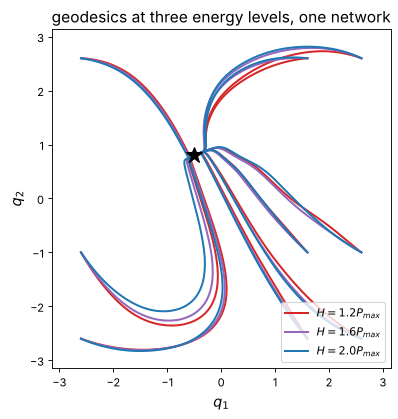

In [7]:
Pm = arm.P_max
G_H = metrics.jacobi_conditioned(arm)
G_Hw = lambda q, w: G_H(q, w[:, 0] * Pm)
m_H = load(nes.NES(*box, cond_lo=[1.1], cond_hi=[2.2]), "checkpoints/cnes_jacobi_paper.pt")
q_goal = np.array([-0.5, 0.8])
starts = np.array([[a, b] for a in [-2.6, 1.6, 2.6] for b in [-2.6, -1.0, 2.6]])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for h, c in [(1.2, "tab:red"), (1.6, "tab:purple"), (2.0, "tab:blue")]:
    ps = geodesics(m_H, G_Hw, q_goal, starts, w=torch.full((len(starts), 1), h), step=0.3, tol=0.03)
    for k, p in enumerate(ps):
        ax.plot(*p.T, color=c, lw=1.8, label=f"$H={h}P_{{max}}$" if k == 0 else None)
ax.plot(*q_goal, "k*", ms=15); ax.legend(loc="lower right")
P.setup_ax(ax, title="geodesics at three energy levels, one network")
plt.show()

## 7. A reactive controller that recovers from pushes

Because the flow is defined everywhere and costs one gradient evaluation (~1 ms), it can be
used directly as a feedback policy.  The arm below follows energy-efficient geodesics under
gravity; after 0.5 s it is pushed, and it simply continues from where it is.  *(Notebook 5.)*

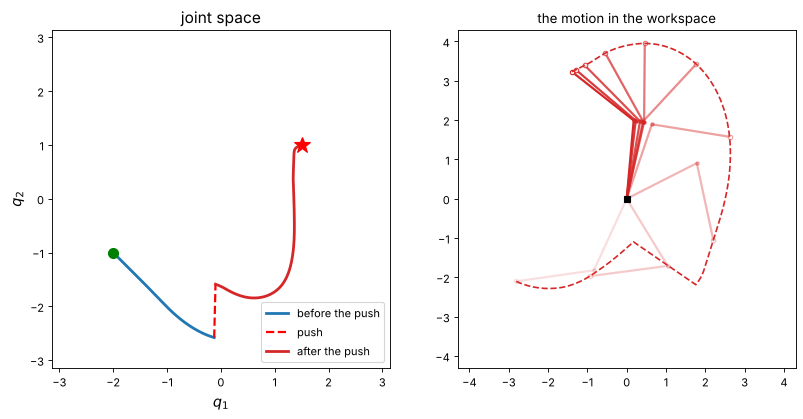

In [8]:
H = 1.2 * Pm
G_J = metrics.jacobi(arm, H)
speed = metrics.jacobi_speed(arm, H)
m_J = load(nes.NES(*box), "checkpoints/nes_jacobi_1.2.pt")
q_start, q_goal = np.array([-2.0, -1.0]), np.array([1.5, 1.0])
g = torch.as_tensor(q_goal[None], dtype=torch.float32)


def policy(q):
    qt = torch.as_tensor(q[None], dtype=torch.float32)
    U, V = nes.geodesic_flow(m_J, g, qt, G_J)
    return ct.blended_velocity(U.double().numpy(), (V * speed(qt)[:, None]).double().numpy(),
                               q[None], q_goal[None], 20 / (2 * H))[0]


q, qd, traj, pushed, dt = q_start.copy(), np.zeros(2), [q_start.copy()], None, 0.005
for k in range(1200):
    if np.linalg.norm(q - q_goal) < 0.02:
        break
    if k == 100:
        q = q + np.array([0.0, 1.0]); pushed = len(traj)
    qd = ct.kinematic_qp(policy(q), q, dt, ct.QD_LIM, -pi, pi, qd, ct.QDD_LIM)
    q = q + dt * qd
    traj.append(q.copy())
traj = np.array(traj)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
axs[0].plot(*traj[:pushed].T, color="tab:blue", lw=2.5, label="before the push")
axs[0].plot(*traj[pushed - 1:pushed + 1].T, "r--", lw=2, label="push")
axs[0].plot(*traj[pushed:].T, color="tab:red", lw=2.5, label="after the push")
axs[0].plot(*q_start, "go", ms=9); axs[0].plot(*q_goal, "r*", ms=15); axs[0].legend(loc="lower right")
P.setup_ax(axs[0], title="joint space")
P.arm_motion(axs[1], arm, traj, "tab:red", n=10)
axs[1].set_title("the motion in the workspace")
plt.show()

## Where to go from here

| Notebook | Topic |
|---|---|
| 1 | Riemannian metrics and geodesics: what a metric is and how it bends shortest paths |
| 2 | Distance fields: the Riemannian eikonal equation, a grid solver, the geodesic flow |
| 3 | The Neural Riemannian Eikonal Solver: learning distances between all pairs of points |
| 4 | Conditioned NES: goals in another space, families of metrics |
| 5 | From geodesic flows to robot control: energy-efficient feedback motion |
| 6 | Designing metrics for tasks: end-effector paths, stability, obstacles |
| A | Geometry-aware sampling (RM-MALA) |